


**Movie Piracy Prediction using Machine Learning and Deep Learning**

**Objective:** Use a pirated movies dataset along with two TMDB movie datasets to answer these questions:

1. **Will a movie be pirated heavily?** (High vs Low piracy) using **ANN, SVM, XGBoost, Decision Tree and KNN**
2. **Will a movie be pirated quickly after release?** (Fast vs Slow) using **Random Forest, KNN and Decision Tree**

**Datasets used:**
- movies_pirated.csv : downloads, views, posted date, release date, rating, industry, language
- movies_ethical.csv : TMDB 5000 movies (budget, revenue, popularity, genres)
- TMDB_movie_dataset_v11.csv : large TMDB dataset (budget, revenue, popularity, votes, genres)

## 1. Importing Libraries

In [234]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
tf.random.set_seed(42)

## 2. Loading the Datasets
Change the file paths below if your files are stored somewhere else.

In [235]:
pirated_movies = pd.read_csv('movies_pirated.csv')
ethical_movies = pd.read_csv('movies_ethical.csv')
ethical2_movies = pd.read_csv('TMDB_movie_dataset_v11.csv', low_memory=False)

print('Pirated movies :', pirated_movies.shape)
print('Ethical movies :', ethical_movies.shape)
print('Ethical2 movies:', ethical2_movies.shape)

Pirated movies : (20548, 15)
Ethical movies : (4803, 24)
Ethical2 movies: (1515783, 24)


In [236]:
pirated_movies.head()

,Unnamed: 0,IMDb-rating,appropriate_for,director,downloads,id,industry,language,posted_date,release_date,run_time,storyline,title,views,writer
0,0,4.8,R,John Swab,304,372092,Hollywood / English,English,"20 Feb, 2023",Jan 28 2023,105,Doc\r\n facilitates a fragile truce between th...,Little Dixie,"2,794",John Swab
1,1,6.4,TV-PG,Paul Ziller,73,372091,Hollywood / English,English,"20 Feb, 2023",Feb 05 2023,84,Caterer\r\n Goldy Berry reunites with detectiv...,Grilling Season: A Curious Caterer Mystery,"1,002",John Christian Plummer
2,2,5.2,R,Ben Wheatley,"1,427",343381,Hollywood / English,"English,Hindi","20 Apr, 2021",Jun 18 2021,1h 47min,As the world searches for a cure to a disastro...,In the Earth,"14,419",Ben Wheatley
3,3,8.1,NaN,Venky Atluri,"1,549",372090,Tollywood,Hindi,"20 Feb, 2023",Feb 17 2023,139,The life of a young man and his struggles agai...,Vaathi,"4,878",Venky Atluri
4,4,4.6,NaN,Shaji Kailas,657,372089,Tollywood,Hindi,"20 Feb, 2023",Jan 26 2023,122,A man named Kalidas gets stranded due to the p...,Alone,"2,438",Rajesh Jayaraman


In [237]:
pirated_movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 20548 entries, 0 to 20547
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       20548 non-null  int64  
 1   IMDb-rating      19707 non-null  float64
 2   appropriate_for  11072 non-null  str    
 3   director         18610 non-null  str    
 4   downloads        20547 non-null  str    
 5   id               20548 non-null  int64  
 6   industry         20547 non-null  str    
 7   language         20002 non-null  str    
 8   posted_date      20547 non-null  str    
 9   release_date     20547 non-null  str    
 10  run_time         18780 non-null  str    
 11  storyline        18847 non-null  str    
 12  title            20547 non-null  str    
 13  views            20547 non-null  str    
 14  writer           18356 non-null  str    
dtypes: float64(1), int64(2), str(12)
memory usage: 2.4 MB


In [238]:
pirated_movies.isnull().sum()

Unnamed: 0            0
IMDb-rating         841
appropriate_for    9476
director           1938
downloads             1
id                    0
industry              1
language            546
posted_date           1
release_date          1
run_time           1768
storyline          1701
title                 1
views                 1
writer             2192
dtype: int64

## 3. Data Cleaning: Pirated Movies Dataset

### 3.1 Dropping unnecessary columns
`Unnamed: 0` is just an index column. `storyline` is text, which we are not using.

In [239]:
pirated = pirated_movies.drop(columns=['Unnamed: 0', 'storyline'])
pirated = pirated.rename(columns={'IMDb-rating': 'imdb_rating', 'appropriate_for': 'age_rating'})
pirated.head()

,imdb_rating,age_rating,director,downloads,id,industry,language,posted_date,release_date,run_time,title,views,writer
0,4.8,R,John Swab,304,372092,Hollywood / English,English,"20 Feb, 2023",Jan 28 2023,105,Little Dixie,"2,794",John Swab
1,6.4,TV-PG,Paul Ziller,73,372091,Hollywood / English,English,"20 Feb, 2023",Feb 05 2023,84,Grilling Season: A Curious Caterer Mystery,"1,002",John Christian Plummer
2,5.2,R,Ben Wheatley,"1,427",343381,Hollywood / English,"English,Hindi","20 Apr, 2021",Jun 18 2021,1h 47min,In the Earth,"14,419",Ben Wheatley
3,8.1,NaN,Venky Atluri,"1,549",372090,Tollywood,Hindi,"20 Feb, 2023",Feb 17 2023,139,Vaathi,"4,878",Venky Atluri
4,4.6,NaN,Shaji Kailas,657,372089,Tollywood,Hindi,"20 Feb, 2023",Jan 26 2023,122,Alone,"2,438",Rajesh Jayaraman


### 3.2 Converting downloads and views to numbers
These columns are stored as text with commas (e.g. `1,234`).

In [240]:
pirated['downloads'] = pd.to_numeric(pirated['downloads'].astype(str).str.replace(',', ''), errors='coerce')
pirated['views'] = pd.to_numeric(pirated['views'].astype(str).str.replace(',', ''), errors='coerce')
pirated['imdb_rating'] = pd.to_numeric(pirated['imdb_rating'], errors='coerce')

pirated[['downloads', 'views', 'imdb_rating']].describe()

,downloads,views,imdb_rating
count,20547.000000,2.054700e+04,19707.000000
mean,10795.238916,3.559551e+04,5.762151
std,23716.181987,6.247242e+04,1.374041
min,0.000000,6.670000e+02,1.100000
25%,855.500000,7.571500e+03,4.800000
50%,2716.000000,1.522200e+04,5.700000
75%,10070.000000,3.657100e+04,6.600000
max,391272.000000,1.638533e+06,9.900000


### 3.3 Converting run time to minutes
Run time is written in different ways like `1h 45min`, `105 min` or `105`.

In [241]:
def runtime_to_minutes(x):
    if pd.isnull(x):
        return np.nan
    x = str(x).replace('min', '').strip()
    try:
        if 'h' in x:
            parts = x.split('h')
            hours = int(parts[0].strip())
            minutes = parts[1].strip()
            if minutes == '':
                minutes = 0
            return hours * 60 + int(minutes)
        else:
            return float(x)
    except:
        return np.nan

pirated['runtime'] = pirated['run_time'].apply(runtime_to_minutes)
pirated = pirated.drop(columns=['run_time'])

print(pirated['runtime'].describe())

count    18779.000000
mean       106.195058
std         23.636743
min          2.000000
25%         90.000000
50%        100.000000
75%        117.000000
max        321.000000
Name: runtime, dtype: float64


### 3.4 Converting dates

In [242]:
pirated['posted_date'] = pd.to_datetime(pirated['posted_date'], errors='coerce', format='mixed')
pirated['release_date'] = pd.to_datetime(pirated['release_date'], errors='coerce', format='mixed')

print('Posted dates :', pirated['posted_date'].min(), 'to', pirated['posted_date'].max())
print('Release dates:', pirated['release_date'].min(), 'to', pirated['release_date'].max())

Posted dates : 1970-01-01 00:00:00 to 2023-02-20 00:00:00
Release dates: 1921-02-05 00:00:00 to 2023-09-23 00:00:00


### 3.5 Handling missing values and duplicates

In [243]:
# rows without title, downloads or posted date are not useful
pirated = pirated.dropna(subset=['title', 'downloads', 'posted_date'])
pirated = pirated.drop_duplicates(subset=['id'])

# fill missing categorical values
pirated['industry'] = pirated['industry'].fillna('Unknown')
pirated['language'] = pirated['language'].fillna('Unknown')
pirated['age_rating'] = pirated['age_rating'].fillna('Unknown')

# some movies have multiple languages like 'English,Hindi' -> keep only the first one
pirated['language'] = pirated['language'].astype(str).str.split(',').str[0].str.strip()

# remove impossible values
pirated.loc[pirated['runtime'] > 400, 'runtime'] = np.nan
pirated.loc[pirated['runtime'] < 20, 'runtime'] = np.nan

print('Shape after cleaning:', pirated.shape)
pirated.isnull().sum()

Shape after cleaning: (17085, 13)


imdb_rating      477
age_rating         0
director        1565
downloads          0
id                 0
industry           0
language           0
posted_date        0
release_date       0
title              0
views              0
writer          1819
runtime         1015
dtype: int64

### 3.6 Creating new features
- **days_since_posted**: older uploads have had more time to collect downloads
- **leak_days**: number of days between release and upload on the piracy site
- **release_year / release_month**

In [244]:
last_date = pirated['posted_date'].max()     # approx. date when the data was collected
first_date = pirated['posted_date'].min()    # when the site started posting

pirated['days_since_posted'] = (last_date - pirated['posted_date']).dt.days
pirated['leak_days'] = (pirated['posted_date'] - pirated['release_date']).dt.days
pirated['release_year'] = pirated['release_date'].dt.year
pirated['release_month'] = pirated['release_date'].dt.month

pirated[['title', 'downloads', 'days_since_posted', 'leak_days', 'release_year']].head()

,title,downloads,days_since_posted,leak_days,release_year
0,Little Dixie,304.0,0,23,2023
1,Grilling Season: A Curious Caterer Mystery,73.0,0,15,2023
2,In the Earth,1427.0,671,-59,2021
3,Vaathi,1549.0,0,3,2023
4,Alone,657.0,0,25,2023


### 3.7 Grouping rare categories
Categories with very few movies are grouped into `Other`.

In [245]:
for col in ['industry', 'language', 'age_rating']:
    counts = pirated[col].value_counts()
    rare = counts[counts < 50].index
    pirated.loc[pirated[col].isin(rare), col] = 'Other'
    print(col, ':', pirated[col].nunique(), 'categories')

industry : 9 categories
language : 13 categories
age_rating : 12 categories


## 4. Data Cleaning: TMDB Datasets
The large TMDB dataset has around a million movies, most of which are very old or unknown.
We reduce it step by step starting with the release date.

In [246]:
tmdb2 = ethical2_movies[['id', 'title', 'release_date', 'vote_average', 'vote_count', 'popularity',
                         'budget', 'revenue', 'genres', 'status', 'adult']].copy()
print('Original size:', tmdb2.shape)

# step 1: date filter (only keep movies in the same date range as the pirated data)
tmdb2['release_date'] = pd.to_datetime(tmdb2['release_date'], errors='coerce')
tmdb2 = tmdb2.dropna(subset=['release_date', 'title'])
tmdb2 = tmdb2[tmdb2['release_date'] >= pirated['release_date'].min()]
print('After date filter:', tmdb2.shape)

# step 2: only released, non-adult movies
tmdb2 = tmdb2[tmdb2['status'] == 'Released']
tmdb2 = tmdb2[tmdb2['adult'].astype(str) == 'False']
print('After status/adult filter:', tmdb2.shape)

# step 3: remove very obscure movies
tmdb2 = tmdb2[tmdb2['vote_count'] >= 10]
print('After vote count filter:', tmdb2.shape)

Original size: (1515783, 11)
After date filter: (1129221, 11)
After status/adult filter: (974488, 11)
After vote count filter: (77513, 11)


In [247]:
# TMDB 5000 dataset (ethical_movies)
tmdb1 = ethical_movies[['id', 'title', 'release_date', 'vote_average', 'vote_count', 'popularity',
                        'budget', 'revenue', 'genres']].copy()
tmdb1['release_date'] = pd.to_datetime(tmdb1['release_date'], errors='coerce')
tmdb1 = tmdb1.dropna(subset=['release_date', 'title'])

# combine both TMDB datasets and remove repeated movies
tmdb = pd.concat([tmdb2.drop(columns=['status', 'adult']), tmdb1])
tmdb = tmdb.drop_duplicates(subset=['id'])

# budget and revenue = 0 means unknown
tmdb['budget'] = tmdb['budget'].replace(0, np.nan)
tmdb['revenue'] = tmdb['revenue'].replace(0, np.nan)

# keep only the first genre
tmdb['genre'] = tmdb['genres'].astype(str).str.split(',').str[0].str.split(' ').str[0]
tmdb.loc[tmdb['genre'] == 'nan', 'genre'] = 'Unknown'

print('Combined TMDB size:', tmdb.shape)

Combined TMDB size: (77692, 10)


## 5. Merging Pirated Data with TMDB Data
Movies are matched using the **title (lowercase, without punctuation)** and the **release year**.
We use a left join so no pirated movie is lost. Unmatched movies just have empty TMDB columns.

In [248]:
pirated['title_clean'] = pirated['title'].astype(str).str.lower().str.replace('[^a-z0-9 ]', '', regex=True).str.strip()
tmdb['title_clean'] = tmdb['title'].astype(str).str.lower().str.replace('[^a-z0-9 ]', '', regex=True).str.strip()
tmdb['release_year'] = tmdb['release_date'].dt.year

# step 4 of reduction: keep only TMDB movies whose title appears in the pirated data
tmdb = tmdb[tmdb['title_clean'].isin(pirated['title_clean'])]
tmdb = tmdb.sort_values('vote_count', ascending=False).drop_duplicates(subset=['title_clean', 'release_year'])
print('TMDB movies left after title filter:', tmdb.shape)

tmdb = tmdb[['title_clean', 'release_year', 'vote_average', 'vote_count', 'popularity', 'budget', 'revenue', 'genre']]
tmdb.columns = ['title_clean', 'release_year', 'tmdb_vote_average', 'tmdb_vote_count', 'tmdb_popularity',
                'tmdb_budget', 'tmdb_revenue', 'genre']

df = pd.merge(pirated, tmdb, on=['title_clean', 'release_year'], how='left')
df['has_tmdb'] = df['tmdb_popularity'].notnull().astype(int)
df['genre'] = df['genre'].fillna('Unknown')

print('Final dataset:', df.shape)
print('Movies matched with TMDB:', df['has_tmdb'].sum(), '(', round(df['has_tmdb'].mean() * 100, 1), '% )')

TMDB movies left after title filter: (14412, 12)
Final dataset: (17085, 25)
Movies matched with TMDB: 9323 ( 54.6 % )


In [249]:
counts = df['genre'].value_counts()
df.loc[df['genre'].isin(counts[counts < 30].index), 'genre'] = 'Other'

df.to_csv('cleaned_piracy_data.csv', index=False)
df.head()

,imdb_rating,age_rating,director,downloads,id,industry,language,posted_date,release_date,title,...,release_year,release_month,title_clean,tmdb_vote_average,tmdb_vote_count,tmdb_popularity,tmdb_budget,tmdb_revenue,genre,has_tmdb
0,4.8,R,John Swab,304.0,372092,Hollywood / English,English,2023-02-20,2023-01-28,Little Dixie,...,2023,1,little dixie,5.836,107.0,38.341,NaN,NaN,Thriller,1
1,6.4,TV-PG,Paul Ziller,73.0,372091,Hollywood / English,English,2023-02-20,2023-02-05,Grilling Season: A Curious Caterer Mystery,...,2023,2,grilling season a curious caterer mystery,NaN,NaN,NaN,NaN,NaN,Unknown,0
2,5.2,R,Ben Wheatley,1427.0,343381,Hollywood / English,English,2021-04-20,2021-06-18,In the Earth,...,2021,6,in the earth,5.760,321.0,13.002,NaN,NaN,Horror,1
3,8.1,Unknown,Venky Atluri,1549.0,372090,Tollywood,Hindi,2023-02-20,2023-02-17,Vaathi,...,2023,2,vaathi,6.600,13.0,3.933,NaN,NaN,Drama,1
4,4.6,Unknown,Shaji Kailas,657.0,372089,Tollywood,Hindi,2023-02-20,2023-01-26,Alone,...,2023,1,alone,NaN,NaN,NaN,NaN,NaN,Unknown,0


## 6. Exploratory Data Analysis

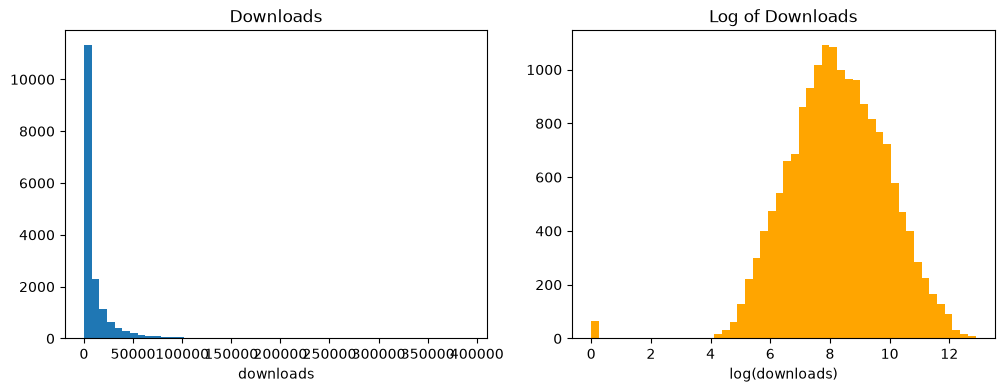

In [250]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(df['downloads'], bins=50)
plt.title('Downloads')
plt.xlabel('downloads')

plt.subplot(1, 2, 2)
plt.hist(np.log1p(df['downloads']), bins=50, color='orange')
plt.title('Log of Downloads')
plt.xlabel('log(downloads)')

plt.show()

Downloads are highly skewed: most movies have few downloads and a small number have a huge amount.

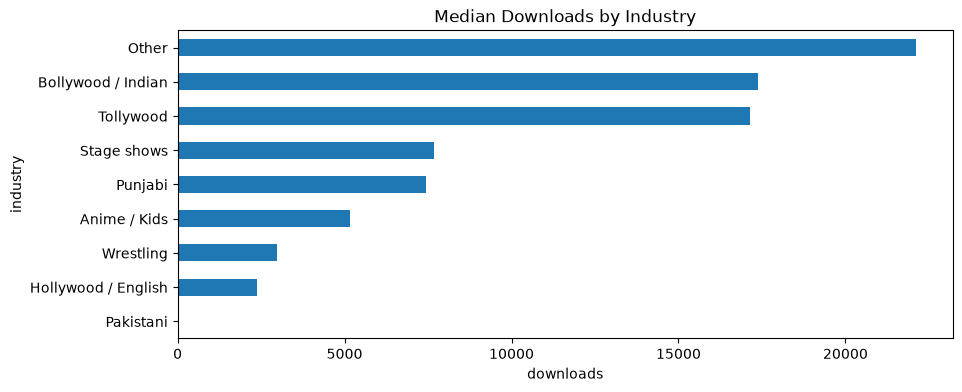

In [251]:
plt.figure(figsize=(10, 4))
df.groupby('industry')['downloads'].median().sort_values().plot(kind='barh')
plt.title('Median Downloads by Industry')
plt.xlabel('downloads')
plt.show()

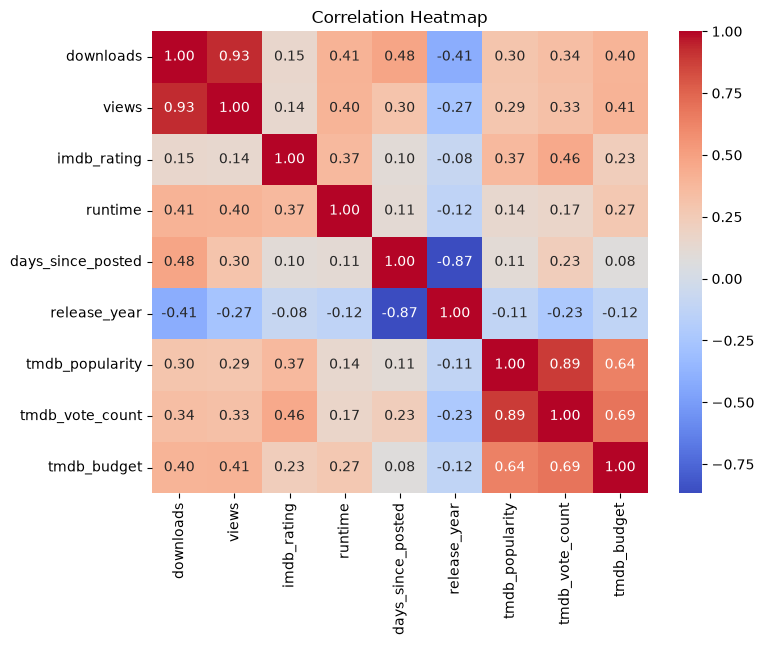

In [252]:
plt.figure(figsize=(8, 6))
corr_cols = ['downloads', 'views', 'imdb_rating', 'runtime', 'days_since_posted', 'release_year',
             'tmdb_popularity', 'tmdb_vote_count', 'tmdb_budget']
sns.heatmap(df[corr_cols].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

## 7. Question 1: Will a movie be pirated heavily? (High vs Low)

### 7.1 Creating the target
Movies are first split into 3 equal groups by downloads (Low / Medium / High).
The **Medium** group is removed because those movies are in-between and overlap with both sides.
- **1 = High piracy**: top third of downloads
- **0 = Low piracy**: bottom third of downloads

Both groups are the same size, so random guessing = 50%.
`views` is **not** used as an input because it is almost the same as downloads.

In [253]:
# rank is used so that movies with equal downloads are still split into equal groups
df['piracy_tier'] = pd.qcut(df['downloads'].rank(method='first'), q=3, labels=[0, 1, 2]).astype(int)
print(df.groupby('piracy_tier')['downloads'].agg(['count', 'min', 'max']))

# keep only Low (0) and High (2) movies
df1 = df[df['piracy_tier'] != 1].copy()
df1['high_piracy'] = (df1['piracy_tier'] == 2).astype(int)

print('\nMovies used for Question 1:', len(df1))
print(df1['high_piracy'].value_counts())

             count     min       max
piracy_tier                         
0             5695     0.0    1901.0
1             5695  1902.0    7972.0
2             5695  7972.0  391272.0

Movies used for Question 1: 11390
high_piracy
0    5695
1    5695
Name: count, dtype: int64


### 7.2 Preparing the features

In [254]:
numeric_cols = ['imdb_rating', 'runtime', 'release_year', 'release_month', 'days_since_posted',
                'has_tmdb', 'tmdb_vote_average', 'tmdb_vote_count', 'tmdb_popularity', 'tmdb_budget']
categorical_cols = ['industry', 'language', 'age_rating', 'genre']

X = df1[numeric_cols + categorical_cols].copy()
y = df1['high_piracy']

# log transform skewed columns
for col in ['days_since_posted', 'tmdb_vote_count', 'tmdb_popularity', 'tmdb_budget']:
    X[col] = np.log1p(X[col])

# fill missing numeric values with the median
for col in numeric_cols:
    X[col] = X[col].fillna(X[col].median())

# one hot encoding
X = pd.get_dummies(X, columns=categorical_cols, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Training set:', X_train.shape)
print('Testing set :', X_test.shape)

Training set: (9112, 64)
Testing set : (2278, 64)


### 7.3 Model 1: Artificial Neural Network (ANN)

In [255]:
ann = Sequential()
ann.add(Input(shape=(X_train_scaled.shape[1],)))
ann.add(Dense(128, activation='relu'))
ann.add(Dropout(0.3))
ann.add(Dense(64, activation='relu'))
ann.add(Dropout(0.2))
ann.add(Dense(32, activation='relu'))
ann.add(Dense(1, activation='sigmoid'))

ann.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005), loss='binary_crossentropy', metrics=['accuracy'])
ann.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,689 (73.00 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)

In [256]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = ann.fit(X_train_scaled, y_train, validation_split=0.2, epochs=100, batch_size=64,
                  callbacks=[early_stop], verbose=1)

Epoch 1/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8022 - loss: 0.4533 - val_accuracy: 0.8859 - val_loss: 0.2768
Epoch 2/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8815 - loss: 0.2886 - val_accuracy: 0.9100 - val_loss: 0.2369
Epoch 3/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8982 - loss: 0.2558 - val_accuracy: 0.9128 - val_loss: 0.2206
Epoch 4/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9031 - loss: 0.2391 - val_accuracy: 0.9177 - val_loss: 0.2140
Epoch 5/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9057 - loss: 0.2312 - val_accuracy: 0.9221 - val_loss: 0.2094
Epoch 6/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9081 - loss: 0.2204 - val_accuracy: 0.9232 - val_loss: 0.2006
Epoch 7/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9116 - loss: 0.2153 - val_accuracy: 0.9238 - val_loss: 0.2013
Epoch 8/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9184 - loss: 0.2071 - val_accu

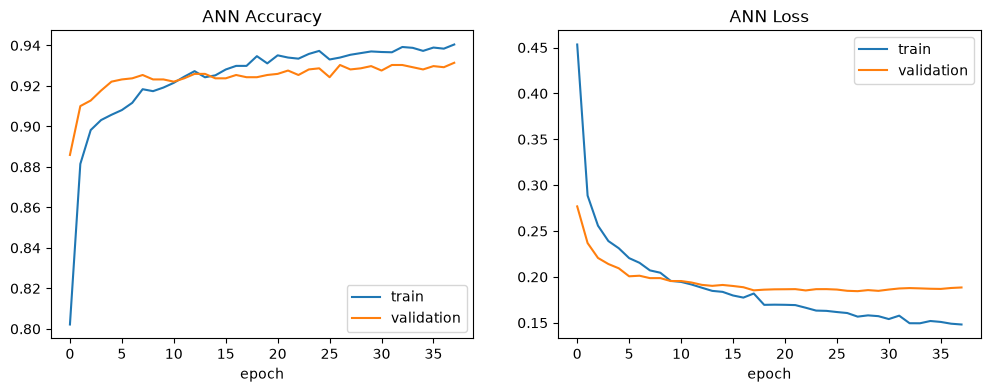

In [257]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.title('ANN Accuracy')
plt.xlabel('epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.title('ANN Loss')
plt.xlabel('epoch')
plt.legend()

plt.show()

In [258]:
ann_pred = (ann.predict(X_test_scaled) > 0.5).astype(int).ravel()

ann_acc = accuracy_score(y_test, ann_pred)
print('ANN Accuracy:', round(ann_acc, 3))
print(classification_report(y_test, ann_pred, target_names=['Low', 'High']))

72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
ANN Accuracy: 0.935
              precision    recall  f1-score   support

         Low       0.94      0.93      0.93      1139
        High       0.93      0.94      0.94      1139

    accuracy                           0.93      2278
   macro avg       0.93      0.93      0.93      2278
weighted avg       0.93      0.93      0.93      2278



### 7.4 Model 2: Support Vector Machine (SVM)
C and gamma are tuned with GridSearchCV on a sample of 5000 movies (SVM is slow on large data).

In [259]:
svm_params = {'C': [1, 10, 50], 'gamma': ['scale', 0.01, 0.001]}

grid_svm = GridSearchCV(SVC(kernel='rbf'), svm_params, cv=3, scoring='accuracy', n_jobs=-1)
grid_svm.fit(X_train_scaled[:5000], y_train[:5000])
print('Best SVM parameters:', grid_svm.best_params_)

svm = SVC(kernel='rbf', C=grid_svm.best_params_['C'], gamma=grid_svm.best_params_['gamma'])
svm.fit(X_train_scaled, y_train)
svm_pred = svm.predict(X_test_scaled)

svm_acc = accuracy_score(y_test, svm_pred)
print('SVM Accuracy:', round(svm_acc, 3))
print(classification_report(y_test, svm_pred, target_names=['Low', 'High']))

Best SVM parameters: {'C': 10, 'gamma': 0.01}
SVM Accuracy: 0.927
              precision    recall  f1-score   support

         Low       0.94      0.92      0.93      1139
        High       0.92      0.94      0.93      1139

    accuracy                           0.93      2278
   macro avg       0.93      0.93      0.93      2278
weighted avg       0.93      0.93      0.93      2278



### 7.5 Model 3: XGBoost
Tuned with GridSearchCV (3-fold cross validation).

In [260]:
xgb_params = {
    'n_estimators': [300, 500],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.03, 0.1]
}

grid_xgb = GridSearchCV(XGBClassifier(random_state=42), xgb_params, cv=3, scoring='accuracy', n_jobs=-1)
grid_xgb.fit(X_train, y_train)
print('Best XGBoost parameters:', grid_xgb.best_params_)

xgb = grid_xgb.best_estimator_
xgb_pred = xgb.predict(X_test)

xgb_acc = accuracy_score(y_test, xgb_pred)
print('XGBoost Accuracy:', round(xgb_acc, 3))
print(classification_report(y_test, xgb_pred, target_names=['Low', 'High']))

Best XGBoost parameters: {'learning_rate': 0.03, 'max_depth': 6, 'n_estimators': 500}
XGBoost Accuracy: 0.935
              precision    recall  f1-score   support

         Low       0.94      0.93      0.94      1139
        High       0.93      0.94      0.94      1139

    accuracy                           0.94      2278
   macro avg       0.94      0.94      0.94      2278
weighted avg       0.94      0.94      0.94      2278



### 7.6 Model 4: Decision Tree
The maximum depth is tuned with GridSearchCV. A small tree (depth 3) is also drawn to show how the decisions are made.

In [261]:
dt_params = {'max_depth': [4, 6, 8, 10, 12], 'min_samples_leaf': [1, 5, 10]}

grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), dt_params, cv=3, scoring='accuracy', n_jobs=-1)
grid_dt.fit(X_train, y_train)
print('Best Decision Tree parameters:', grid_dt.best_params_)

dt = grid_dt.best_estimator_
dt_pred = dt.predict(X_test)

dt_acc = accuracy_score(y_test, dt_pred)
print('Decision Tree Accuracy:', round(dt_acc, 3))
print(classification_report(y_test, dt_pred, target_names=['Low', 'High']))

Best Decision Tree parameters: {'max_depth': 8, 'min_samples_leaf': 1}
Decision Tree Accuracy: 0.922
              precision    recall  f1-score   support

         Low       0.92      0.93      0.92      1139
        High       0.93      0.92      0.92      1139

    accuracy                           0.92      2278
   macro avg       0.92      0.92      0.92      2278
weighted avg       0.92      0.92      0.92      2278



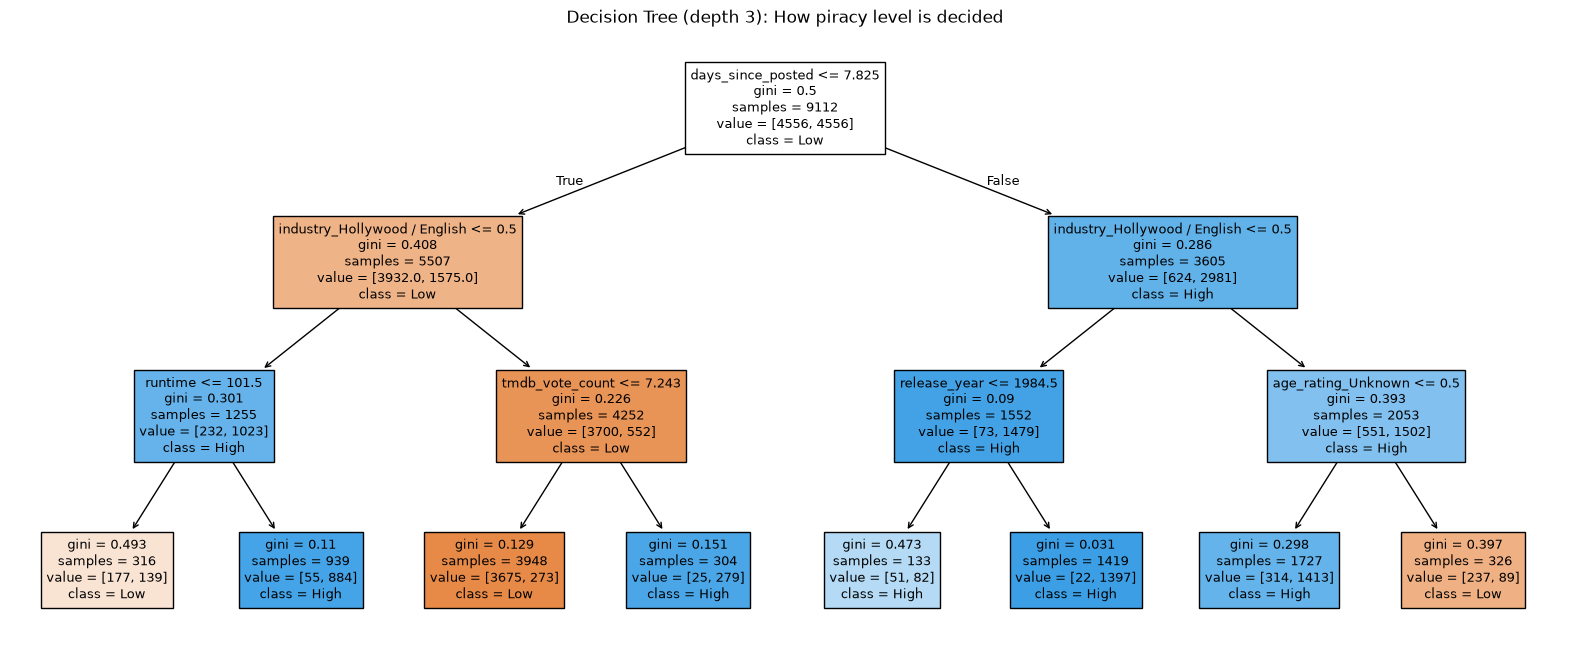

In [262]:
small_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
small_tree.fit(X_train, y_train)

plt.figure(figsize=(20, 8))
plot_tree(small_tree, feature_names=X.columns, class_names=['Low', 'High'], filled=True, fontsize=9)
plt.title('Decision Tree (depth 3): How piracy level is decided')
plt.show()

### 7.7 Model 5: K-Nearest Neighbours (KNN)
KNN uses distances between movies, so it needs the scaled data. We try different values of K and pick the best one using cross validation.

K = 3  accuracy = 0.9
K = 5  accuracy = 0.899
K = 7  accuracy = 0.897
K = 11  accuracy = 0.891
K = 15  accuracy = 0.889
K = 21  accuracy = 0.883
K = 31  accuracy = 0.877


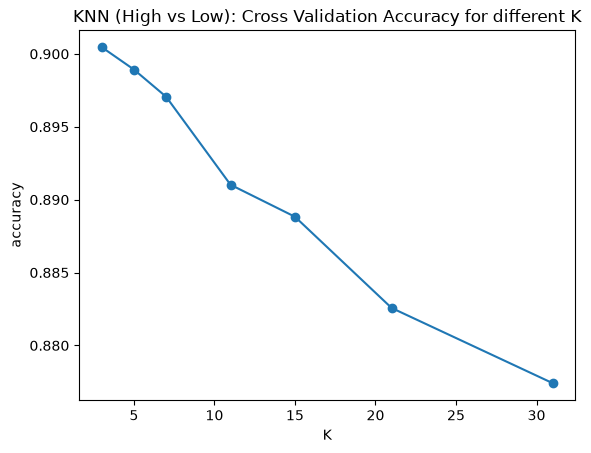

Best K: 3


In [263]:
k_values = [3, 5, 7, 11, 15, 21, 31]
cv_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy').mean()
    cv_scores.append(score)
    print('K =', k, ' accuracy =', round(score, 3))

plt.plot(k_values, cv_scores, marker='o')
plt.title('KNN (High vs Low): Cross Validation Accuracy for different K')
plt.xlabel('K')
plt.ylabel('accuracy')
plt.show()

best_k1 = k_values[np.argmax(cv_scores)]
print('Best K:', best_k1)

In [264]:
knn1 = KNeighborsClassifier(n_neighbors=best_k1)
knn1.fit(X_train_scaled, y_train)
knn1_pred = knn1.predict(X_test_scaled)

knn1_acc = accuracy_score(y_test, knn1_pred)
print('KNN Accuracy:', round(knn1_acc, 3))
print(classification_report(y_test, knn1_pred, target_names=['Low', 'High']))

KNN Accuracy: 0.908
              precision    recall  f1-score   support

         Low       0.91      0.91      0.91      1139
        High       0.91      0.91      0.91      1139

    accuracy                           0.91      2278
   macro avg       0.91      0.91      0.91      2278
weighted avg       0.91      0.91      0.91      2278



### 7.8 Comparing the Models

           Model  Accuracy  F1 Score
0  Decision Tree     0.922     0.922
1            ANN     0.935     0.935
2            SVM     0.927     0.927
3        XGBoost     0.935     0.935
4            KNN     0.908     0.908


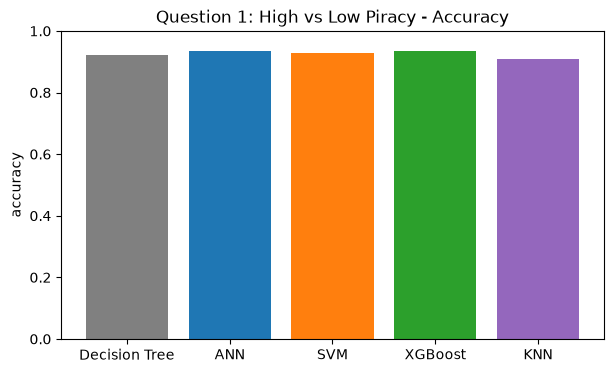

In [265]:
results1 = pd.DataFrame({
    'Model': ['Decision Tree', 'ANN', 'SVM', 'XGBoost', 'KNN'],
    'Accuracy': [dt_acc, ann_acc, svm_acc, xgb_acc, knn1_acc],
    'F1 Score': [f1_score(y_test, dt_pred, average='macro'),
                 f1_score(y_test, ann_pred, average='macro'),
                 f1_score(y_test, svm_pred, average='macro'),
                 f1_score(y_test, xgb_pred, average='macro'),
                 f1_score(y_test, knn1_pred, average='macro')]
}).round(3)
print(results1)

plt.figure(figsize=(7, 4))
plt.bar(results1['Model'], results1['Accuracy'], color=['grey', 'tab:blue', 'tab:orange', 'tab:green', 'tab:purple'])
plt.title('Question 1: High vs Low Piracy - Accuracy')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.show()

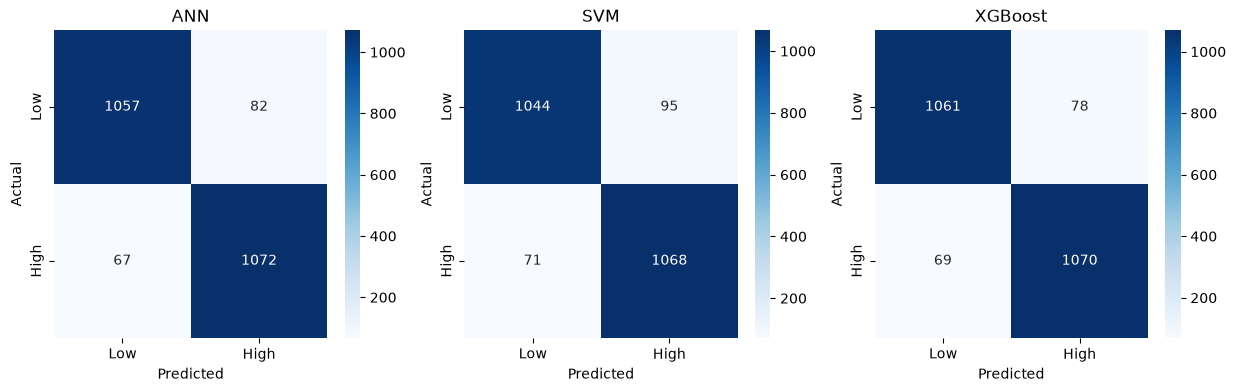

In [266]:
labels = ['Low', 'High']
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.heatmap(confusion_matrix(y_test, ann_pred), annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('ANN'); plt.xlabel('Predicted'); plt.ylabel('Actual')

plt.subplot(1, 3, 2)
sns.heatmap(confusion_matrix(y_test, svm_pred), annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('SVM'); plt.xlabel('Predicted'); plt.ylabel('Actual')

plt.subplot(1, 3, 3)
sns.heatmap(confusion_matrix(y_test, xgb_pred), annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('XGBoost'); plt.xlabel('Predicted'); plt.ylabel('Actual')

plt.show()

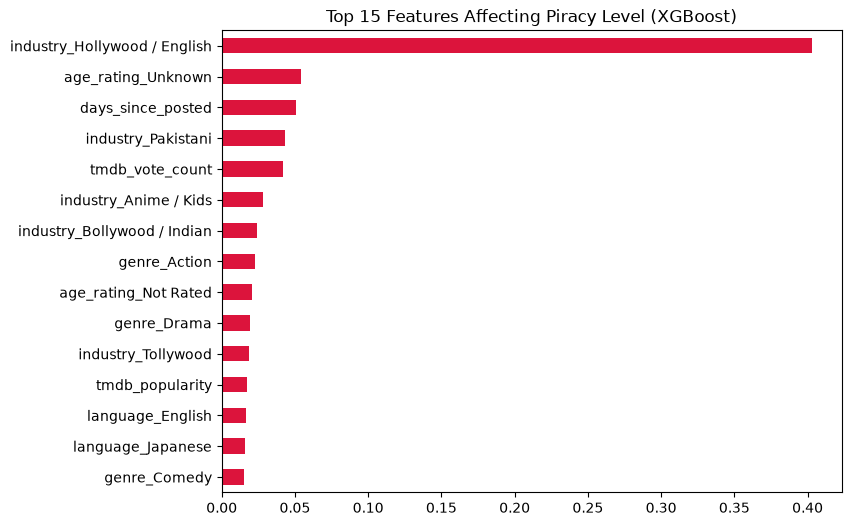

In [267]:
importance = pd.Series(xgb.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
importance.head(15).sort_values().plot(kind='barh', color='crimson')
plt.title('Top 15 Features Affecting Piracy Level (XGBoost)')
plt.show()

## 8. Question 2: Will a movie be pirated quickly? (Fast vs Slow)

### 8.1 Selecting the right movies
`posted_date` is when **this site** uploaded the movie. For old movies (e.g. a 1995 movie uploaded in 2022)
the leak days are meaningless. So we only keep:
- movies released after the site started posting (5th percentile of posted dates, to ignore a few outlier dates)
- movies uploaded **within one year** of release (0 to 365 days)

In [268]:
site_start = df['posted_date'].quantile(0.05)
print('Site start date used:', site_start.date())

df2 = df[df['release_date'] >= site_start].copy()
print('Movies released after the site started:', len(df2))
print('Uploaded before release (removed):', (df2['leak_days'] < 0).sum())
print('Uploaded more than 1 year after release (removed):', (df2['leak_days'] > 365).sum())

df2 = df2[(df2['leak_days'] >= 0) & (df2['leak_days'] <= 365)]
print('Movies used for Question 2:', len(df2))
print(df2['leak_days'].describe())

Site start date used: 2009-07-21
Movies released after the site started: 14115
Uploaded before release (removed): 919
Uploaded more than 1 year after release (removed): 1082
Movies used for Question 2: 12114
count    12114.000000
mean        51.156348
std         83.471422
min          0.000000
25%          1.000000
50%          7.000000
75%         71.000000
max        365.000000
Name: leak_days, dtype: float64


### 8.2 Creating the target
- **1 = Fast**: leaked in fewer days than the median
- **0 = Slow**: leaked at or after the median

Using the median gives two equal groups, so random guessing = 50%.

In [269]:
median_leak = df2['leak_days'].median()
df2['fast_leak'] = (df2['leak_days'] < median_leak).astype(int)

print('Median leak days:', median_leak)
print('Fast = pirated within', int(median_leak), 'days of release')
print(df2['fast_leak'].value_counts())

Median leak days: 7.0
Fast = pirated within 7 days of release
fast_leak
0    6207
1    5907
Name: count, dtype: int64


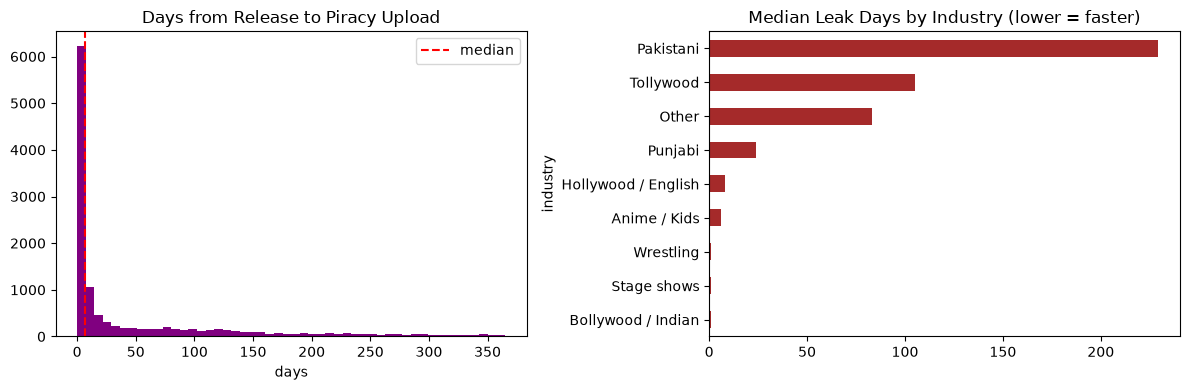

In [270]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(df2['leak_days'], bins=50, color='purple')
plt.axvline(median_leak, color='red', linestyle='--', label='median')
plt.title('Days from Release to Piracy Upload')
plt.xlabel('days')
plt.legend()

plt.subplot(1, 2, 2)
df2.groupby('industry')['leak_days'].median().sort_values().plot(kind='barh', color='brown')
plt.title('Median Leak Days by Industry (lower = faster)')

plt.tight_layout()
plt.show()

### 8.3 Preparing the features
`release_year` and `days_since_posted` are not used here, because together they directly give away the leak days.

In [271]:
numeric_cols2 = ['imdb_rating', 'runtime', 'release_month', 'has_tmdb', 'tmdb_vote_average',
                 'tmdb_vote_count', 'tmdb_popularity', 'tmdb_budget']

X2 = df2[numeric_cols2 + categorical_cols].copy()
y2 = df2['fast_leak']

for col in ['tmdb_vote_count', 'tmdb_popularity', 'tmdb_budget']:
    X2[col] = np.log1p(X2[col])
for col in numeric_cols2:
    X2[col] = X2[col].fillna(X2[col].median())

X2 = pd.get_dummies(X2, columns=categorical_cols, dtype=int)

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42, stratify=y2)

scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

print('Training set:', X2_train.shape)
print('Testing set :', X2_test.shape)

Training set: (9691, 62)
Testing set : (2423, 62)


### 8.4 Model 4: Random Forest
Tuned with GridSearchCV.

In [272]:
rf_params = {
    'n_estimators': [200, 400],
    'max_depth': [None, 10, 20],
    'min_samples_leaf': [1, 3, 5]
}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), rf_params, cv=3, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X2_train, y2_train)
print('Best Random Forest parameters:', grid_rf.best_params_)

rf = grid_rf.best_estimator_
rf_pred = rf.predict(X2_test)

rf_acc = accuracy_score(y2_test, rf_pred)
print('Random Forest Accuracy:', round(rf_acc, 3))
print(classification_report(y2_test, rf_pred, target_names=['Slow', 'Fast']))

Best Random Forest parameters: {'max_depth': 20, 'min_samples_leaf': 3, 'n_estimators': 200}
Random Forest Accuracy: 0.659
              precision    recall  f1-score   support

        Slow       0.65      0.72      0.68      1242
        Fast       0.67      0.59      0.63      1181

    accuracy                           0.66      2423
   macro avg       0.66      0.66      0.66      2423
weighted avg       0.66      0.66      0.66      2423



### 8.5 Model 5: K-Nearest Neighbours (KNN)
We try different values of K and pick the best one using cross validation.

K = 3  accuracy = 0.6
K = 5  accuracy = 0.611
K = 7  accuracy = 0.614
K = 11  accuracy = 0.62
K = 15  accuracy = 0.624
K = 21  accuracy = 0.622
K = 31  accuracy = 0.627


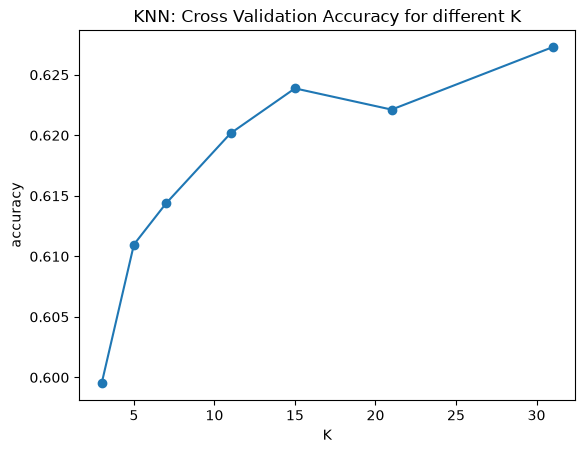

Best K: 31


In [273]:
k_values = [3, 5, 7, 11, 15, 21, 31]
cv_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, X2_train_scaled, y2_train, cv=5, scoring='accuracy').mean()
    cv_scores.append(score)
    print('K =', k, ' accuracy =', round(score, 3))

plt.plot(k_values, cv_scores, marker='o')
plt.title('KNN: Cross Validation Accuracy for different K')
plt.xlabel('K')
plt.ylabel('accuracy')
plt.show()

best_k = k_values[np.argmax(cv_scores)]
print('Best K:', best_k)

In [274]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X2_train_scaled, y2_train)
knn_pred = knn.predict(X2_test_scaled)

knn_acc = accuracy_score(y2_test, knn_pred)
print('KNN Accuracy:', round(knn_acc, 3))
print(classification_report(y2_test, knn_pred, target_names=['Slow', 'Fast']))

KNN Accuracy: 0.622
              precision    recall  f1-score   support

        Slow       0.61      0.74      0.67      1242
        Fast       0.65      0.50      0.56      1181

    accuracy                           0.62      2423
   macro avg       0.63      0.62      0.62      2423
weighted avg       0.63      0.62      0.62      2423



### 8.6 Model 6: Decision Tree
The maximum depth is tuned with GridSearchCV.

In [275]:
dt2_params = {'max_depth': [4, 6, 8, 10, 12], 'min_samples_leaf': [1, 5, 10]}

grid_dt2 = GridSearchCV(DecisionTreeClassifier(random_state=42), dt2_params, cv=3, scoring='accuracy', n_jobs=-1)
grid_dt2.fit(X2_train, y2_train)
print('Best Decision Tree parameters:', grid_dt2.best_params_)

dt2 = grid_dt2.best_estimator_
dt2_pred = dt2.predict(X2_test)

dt2_acc = accuracy_score(y2_test, dt2_pred)
print('Decision Tree Accuracy:', round(dt2_acc, 3))
print(classification_report(y2_test, dt2_pred, target_names=['Slow', 'Fast']))

Best Decision Tree parameters: {'max_depth': 6, 'min_samples_leaf': 1}
Decision Tree Accuracy: 0.605
              precision    recall  f1-score   support

        Slow       0.61      0.66      0.63      1242
        Fast       0.60      0.55      0.57      1181

    accuracy                           0.60      2423
   macro avg       0.60      0.60      0.60      2423
weighted avg       0.60      0.60      0.60      2423



### 8.7 Comparing the Models

           Model  Accuracy  F1 Score
0  Decision Tree     0.605     0.603
1  Random Forest     0.659     0.656
2            KNN     0.622     0.615


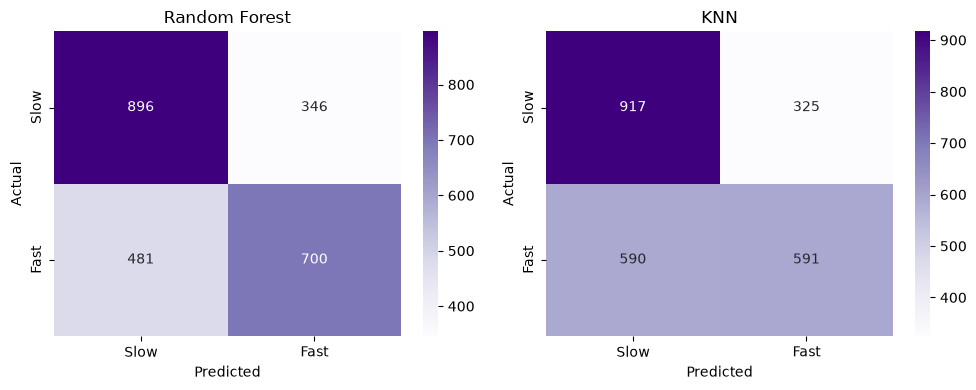

In [276]:
results2 = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest', 'KNN'],
    'Accuracy': [dt2_acc, rf_acc, knn_acc],
    'F1 Score': [f1_score(y2_test, dt2_pred, average='macro'),
                 f1_score(y2_test, rf_pred, average='macro'),
                 f1_score(y2_test, knn_pred, average='macro')]
}).round(3)
print(results2)

labels = ['Slow', 'Fast']
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.heatmap(confusion_matrix(y2_test, rf_pred), annot=True, fmt='d', cmap='Purples', xticklabels=labels, yticklabels=labels)
plt.title('Random Forest'); plt.xlabel('Predicted'); plt.ylabel('Actual')

plt.subplot(1, 2, 2)
sns.heatmap(confusion_matrix(y2_test, knn_pred), annot=True, fmt='d', cmap='Purples', xticklabels=labels, yticklabels=labels)
plt.title('KNN'); plt.xlabel('Predicted'); plt.ylabel('Actual')

plt.tight_layout()
plt.show()

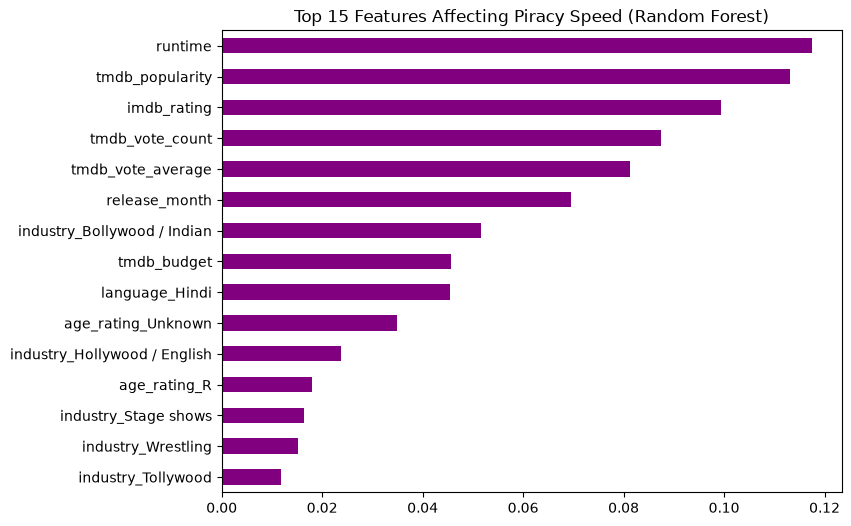

In [277]:
importance2 = pd.Series(rf.feature_importances_, index=X2.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
importance2.head(15).sort_values().plot(kind='barh', color='purple')
plt.title('Top 15 Features Affecting Piracy Speed (Random Forest)')
plt.show()

## 9. Final Results

In [278]:

print(' High vs Low Piracy (Decision Tree, ANN, SVM, XGBoost, KNN)')

print(results1.to_string(index=False))
print()

print(' Fast vs Slow Piracy (Decision Tree, Random Forest, KNN)')
print('Fast = pirated within', int(median_leak), 'days of release')

print(results2.to_string(index=False))

 High vs Low Piracy (Decision Tree, ANN, SVM, XGBoost, KNN)
        Model  Accuracy  F1 Score
Decision Tree     0.922     0.922
          ANN     0.935     0.935
          SVM     0.927     0.927
      XGBoost     0.935     0.935
          KNN     0.908     0.908

 Fast vs Slow Piracy (Decision Tree, Random Forest, KNN)
Fast = pirated within 7 days of release
        Model  Accuracy  F1 Score
Decision Tree     0.605     0.603
Random Forest     0.659     0.656
          KNN     0.622     0.615


## 10. Conclusion
- **1:** By comparing the most pirated and least pirated movies, a movie's details (industry, rating, popularity, time online) predict whether it will be heavily pirated
  much better than random guessing. Tree based XGBoost performs about as well as or better than the ANN on this tabular data.
- **2:** Leak speed is harder to predict than piracy level, because it depends on things not in the data
  (OTT release dates, print quality, release region).

